# India CPI Inflation Analytics Case Study

**Author:** Garvit Gaur

## Objective
Explore India's Consumer Price Index (CPI) time series across Rural, Urban, and Rural+Urban sectors. The analysis covers category-level price index trends, year-on-year inflation, food-price volatility, COVID-era comparisons, and relationships with the Fuel and light index.

**Data period:** January 2013 to May 2023 (as present in the supplied workbook).

> CPI index levels are not themselves inflation rates. This notebook uses the workbook's provided `MoM_Inflation_%` and `YoY_Inflation_%` fields where available. Correlation is descriptive and does not establish causation.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("data")
if not DATA_DIR.exists():
    DATA_DIR = Path("../data")

cpi = pd.read_csv(DATA_DIR / "cpi_clean_data.csv")
category_map = pd.read_csv(DATA_DIR / "category_mapping.csv")

cpi["Date"] = pd.to_datetime(dict(
    year=cpi["Year"], month=cpi["Month Number"], day=1
))
cpi["CPI_Index"] = pd.to_numeric(cpi["CPI_Index"], errors="coerce")
cpi["MoM_Inflation_%"] = pd.to_numeric(cpi["MoM_Inflation_%"], errors="coerce")
cpi["YoY_Inflation_%"] = pd.to_numeric(cpi["YoY_Inflation_%"], errors="coerce")

print("Rows:", len(cpi))
print("Date range:", cpi["Date"].min().date(), "to", cpi["Date"].max().date())
print("Sectors:", sorted(cpi["Sector"].dropna().unique()))
print("Categories:", cpi["Category"].nunique())
print("Duplicate rows:", cpi.duplicated().sum())
print("\nMissing values:\n", cpi.isna().sum())


Rows: 10044
Date range: 2013-01-01 to 2023-05-01
Sectors: ['Rural', 'Rural+Urban', 'Urban']
Categories: 27
Duplicate rows: 0

Missing values:
 Sector                 0
Year                   0
Month                  0
Month Number           0
Date                   0
Category               0
CPI_Index              0
Broader_Category       0
MoM_Inflation_%      891
YoY_Inflation_%     1053
dtype: int64


## 1. Category coverage and CPI index profile

The workbook includes 27 category labels mapped into broader groups. The mapping is used for grouped analysis. Category counts are descriptive and should not be interpreted as official CPI expenditure weights.

In [2]:
category_profile = (
    category_map.groupby("Broader_Bucket")["Category"]
    .nunique().sort_values(ascending=False).rename("category_count")
)
display(category_profile.to_frame())

sector_summary = (
    cpi.groupby("Sector")
    .agg(records=("CPI_Index", "size"),
         avg_cpi_index=("CPI_Index", "mean"),
         min_cpi_index=("CPI_Index", "min"),
         max_cpi_index=("CPI_Index", "max"))
    .round(2)
)
display(sector_summary)


,category_count
Broader_Bucket,
Food,13
Recreation,4
Clothing,3
Education,1
Healthcare,1
Energy,1
Household,1
Housing,1
Overall,1


,records,avg_cpi_index,min_cpi_index,max_cpi_index
Sector,,,,
Rural,3348,140.55,92.5,225.2
Rural+Urban,3348,139.51,90.4,230.5
Urban,3348,138.39,85.3,245.3


## 2. Year-on-year inflation trend

This section uses the `General index` series for the combined Rural+Urban sector and averages the supplied monthly YoY inflation values by calendar year.

,Average YoY inflation (%)
Year,
2017,3.33
2018,3.97
2019,3.77
2020,6.34
2021,5.35
2022,6.62
2023,5.58


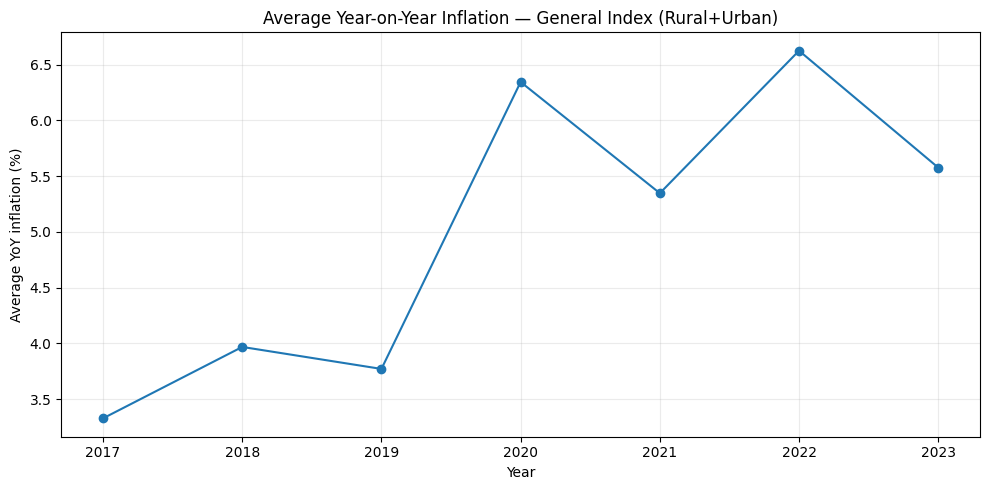

In [3]:
general = cpi[
    (cpi["Sector"] == "Rural+Urban") &
    (cpi["Category"] == "General index")
].copy()

annual_yoy = (
    general.dropna(subset=["YoY_Inflation_%"])
    .groupby("Year")["YoY_Inflation_%"].mean()
    .loc[lambda s: s.index >= 2017]
)
display(annual_yoy.round(2).rename("Average YoY inflation (%)").to_frame())

plt.figure(figsize=(10, 5))
annual_yoy.plot(marker="o")
plt.title("Average Year-on-Year Inflation — General Index (Rural+Urban)")
plt.xlabel("Year")
plt.ylabel("Average YoY inflation (%)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 3. Food inflation volatility (June 2022–May 2023)

Compare monthly inflation across food sub-categories in the selected 12-month window. The volatility measure below is the range (maximum minus minimum) of monthly percentage changes.

,avg_mom,min_mom,max_mom,volatility
Category,,,,
Vegetables,-0.26,-12.67,4.23,16.90
Egg,0.48,-9.92,6.14,16.07
Fruits,0.09,-4.16,7.08,11.24
Oils and fats,-1.50,-4.22,1.29,5.51
Meat and fish,-0.17,-3.05,2.39,5.44
Cereals and products,0.85,-0.34,2.43,2.77
Spices,1.37,0.00,2.40,2.40
Food and beverages,0.26,-1.35,1.01,2.36
Sugar and Confectionery,0.28,-0.91,1.15,2.06


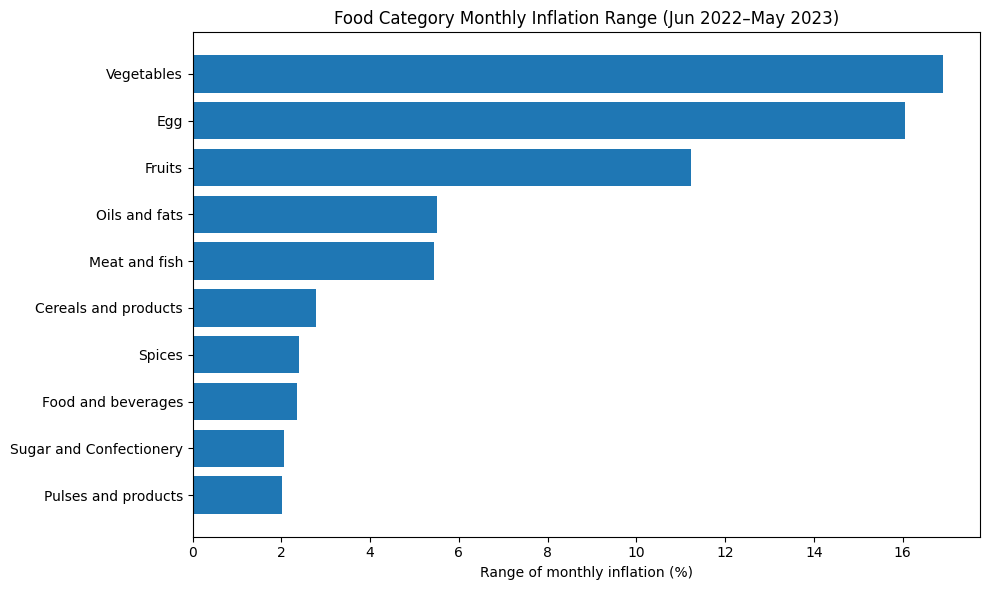

In [4]:
food_categories = category_map.loc[
    category_map["Broader_Bucket"] == "Food", "Category"
].tolist()
food_window = cpi[
    (cpi["Sector"] == "Rural+Urban") &
    (cpi["Category"].isin(food_categories)) &
    (cpi["Date"].between("2022-06-01", "2023-05-01"))
].copy()

food_volatility = (
    food_window.groupby("Category")["MoM_Inflation_%"]
    .agg(avg_mom="mean", min_mom="min", max_mom="max", volatility=lambda x: x.max()-x.min())
    .sort_values("volatility", ascending=False)
)
display(food_volatility.round(2))

top_food = food_volatility.head(10).sort_values("volatility")
plt.figure(figsize=(10, 6))
plt.barh(top_food.index, top_food["volatility"])
plt.title("Food Category Monthly Inflation Range (Jun 2022–May 2023)")
plt.xlabel("Range of monthly inflation (%)")
plt.tight_layout()
plt.show()


## 4. Pre-COVID vs post-COVID inflation comparison

Compare average monthly YoY inflation for January 2018–February 2020 (pre-COVID) and March 2020–December 2021 (post-COVID). The comparison uses categories that have YoY values in the supplied dataset.

,Pre_COVID_YoY,Post_COVID_YoY,Change_pp
Category,,,
Oils and fats,2.20,22.26,20.05
Pulses and products,-1.80,12.21,14.01
Non-alcoholic beverages,2.43,10.13,7.70
Egg,4.04,11.16,7.12
Transport and communication,3.67,9.72,6.05
Spices,2.60,8.26,5.66
Meat and fish,6.13,11.77,5.65
Sugar and Confectionery,-2.89,1.94,4.82
Fuel and light,3.88,6.92,3.04


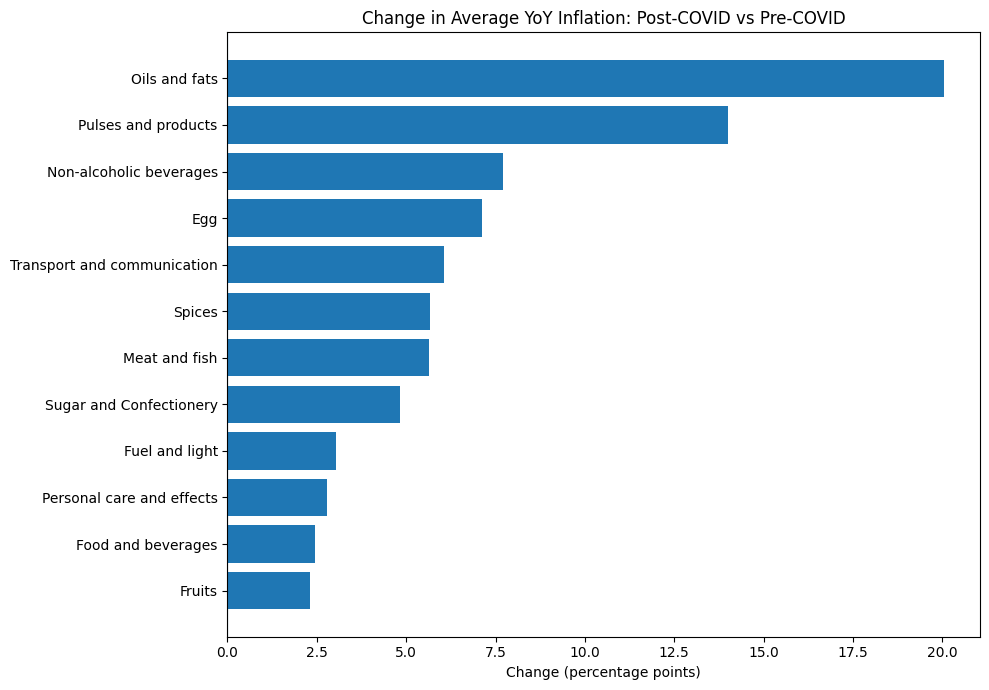

In [5]:
pre_start, pre_end = "2018-01-01", "2020-02-01"
post_start, post_end = "2020-03-01", "2021-12-01"

covid_base = cpi[cpi["Sector"] == "Rural+Urban"].copy()
pre = covid_base[covid_base["Date"].between(pre_start, pre_end)]
post = covid_base[covid_base["Date"].between(post_start, post_end)]

covid_compare = pd.DataFrame({
    "Pre_COVID_YoY": pre.groupby("Category")["YoY_Inflation_%"].mean(),
    "Post_COVID_YoY": post.groupby("Category")["YoY_Inflation_%"].mean()
})
covid_compare["Change_pp"] = covid_compare["Post_COVID_YoY"] - covid_compare["Pre_COVID_YoY"]
covid_compare = covid_compare.dropna().sort_values("Change_pp", ascending=False)
display(covid_compare.round(2))

plot_data = covid_compare.head(12).sort_values("Change_pp")
plt.figure(figsize=(10, 7))
plt.barh(plot_data.index, plot_data["Change_pp"])
plt.axvline(0, linewidth=0.8)
plt.title("Change in Average YoY Inflation: Post-COVID vs Pre-COVID")
plt.xlabel("Change (percentage points)")
plt.tight_layout()
plt.show()


## 5. Fuel and light CPI relationship (January 2021–April 2023)

Use the Fuel and light CPI index as a proxy series and calculate Pearson correlations with other category CPI index series for the Rural+Urban sector. This is an exploratory association, not evidence that fuel prices caused changes in other categories.

,Correlation with Fuel and light CPI
Category,
General index,0.987
Footwear,0.987
Clothing and footwear,0.985
Clothing,0.985
Recreation and amusement,0.984
Miscellaneous,0.983
"Prepared meals, snacks, sweets etc.",0.983
Household goods and services,0.982
Education,0.979


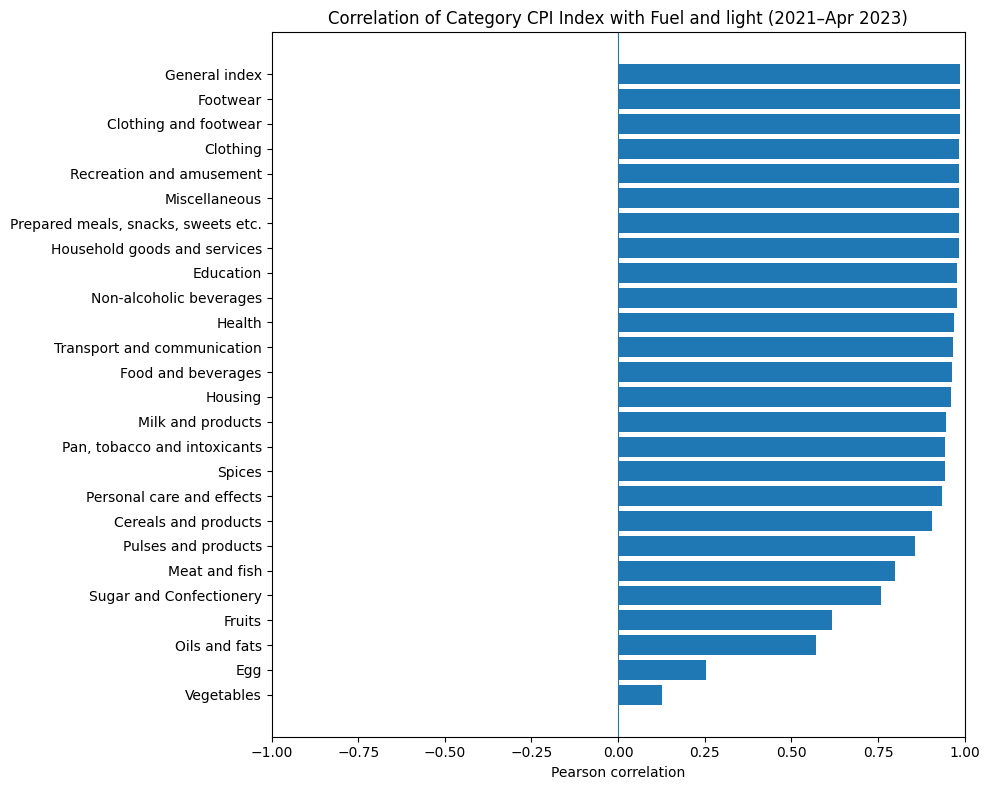

In [6]:
oil_window = cpi[
    (cpi["Sector"] == "Rural+Urban") &
    (cpi["Date"].between("2021-01-01", "2023-04-01"))
]
wide = oil_window.pivot_table(
    index="Date", columns="Category", values="CPI_Index", aggfunc="mean"
)
if "Fuel and light" not in wide.columns:
    raise ValueError("Fuel and light category is missing from the CPI data.")

fuel_corr = wide.corr(numeric_only=True)["Fuel and light"].drop("Fuel and light")
fuel_corr = fuel_corr.sort_values(ascending=False)
display(fuel_corr.round(3).rename("Correlation with Fuel and light CPI").to_frame())

corr_plot = fuel_corr.sort_values()
plt.figure(figsize=(10, 8))
plt.barh(corr_plot.index, corr_plot.values)
plt.axvline(0, linewidth=0.8)
plt.xlim(-1, 1)
plt.title("Correlation of Category CPI Index with Fuel and light (2021–Apr 2023)")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()


## Key interpretation and limitations

- The analysis covers the dates and categories present in the workbook, ending in May 2023.
- Missing YoY and MoM values are expected at the beginning of each time series because prior comparison periods are unavailable.
- Category mapping and the original workbook's Q1–Q5 pivot/summary tabs are retained in the repository for traceability.
- The workbook's pivot outputs contain pre-calculated interpretations. This notebook recomputes the core analyses from the structured clean-data table.
- The workbook does not provide CPI expenditure weights or a separate crude-oil price series. Therefore, equal-category summaries and Fuel and light correlations must not be presented as official CPI contribution weights or direct crude-oil causal effects.
